# comprension_eda.ipynb
## Comprensión del negocio y Análisis Exploratorio de Datos (EDA)

**Caso de negocio:** una entidad financiera otorga créditos y necesita **predecir si un cliente pagará a tiempo** (`Pago_atiempo` = 1) **o no** (`Pago_atiempo` = 0). Un buen modelo permite aprobar créditos con menos riesgo y anticipar la cartera en mora.

**Variable objetivo:** `Pago_atiempo` (clasificación binaria).

**Lo que hace este notebook:**
1. Explorar y describir los datos.
2. Unificar nulos y corregir tipos de dato.
3. Limpiar `tendencia_ingresos` e imputar nulos numéricos con la media.
4. Calcular correlaciones y eliminar variables irrelevantes o redundantes.
5. Hacer análisis univariable, bivariable y multivariable.
6. Definir reglas de validación y variables derivadas para las siguientes etapas.

## 1. Exploración inicial de los datos

In [1]:
# Importar librerías
import pandas as pd                 # tablas de datos
import numpy as np                  # cálculos numéricos
import matplotlib.pyplot as plt     # gráficos básicos
import seaborn as sns               # gráficos estadísticos

# Opciones para ver más columnas y que los gráficos se vean bien
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

In [2]:
# Leer la base de datos (el CSV lo generó Cargar_datos.ipynb)
df = pd.read_csv("../Base_de_datos.csv")

print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (10763, 23)


,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,4,2025-01-07 14:40:36,1852560.0,12,32,Empleado,3500000,1000000,128650,95.227787,795.0,0,2,0.0,0.0,NaN,NaN,0,0,0,916148.0,Creciente,1
1,4,2025-01-09 11:18:48,3181080.0,6,34,Empleado,5000000,2000000,441817,95.227787,796.0,0,7,0.0,0.0,NaN,NaN,0,0,0,4473774.0,Creciente,1
2,9,2024-12-26 18:52:57,670200.0,5,34,Independiente,5000000,2000000,108632,95.227787,727.0,5,0,0.0,274561.0,274561.0,NaN,2,0,1,NaN,NaN,1
3,9,2024-12-04 14:20:50,506806.8,2,25,Independiente,3000000,900000,199684,95.227787,864.0,8,1,0.0,27564.0,27564.0,NaN,1,0,6,NaN,NaN,1
4,4,2025-04-30 18:41:57,999780.0,10,26,Empleado,2000000,600000,92509,95.227787,771.0,0,3,0.0,0.0,NaN,NaN,0,0,0,61000.0,Creciente,1


In [3]:
# Información general: nombre de columna, cantidad de datos no nulos y tipo
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   tipo_credito                   10763 non-null  int64  
 1   fecha_prestamo                 10763 non-null  str    
 2   capital_prestado               10763 non-null  float64
 3   plazo_meses                    10763 non-null  int64  
 4   edad_cliente                   10763 non-null  int64  
 5   tipo_laboral                   10763 non-null  str    
 6   salario_cliente                10763 non-null  int64  
 7   total_otros_prestamos          10763 non-null  int64  
 8   cuota_pactada                  10763 non-null  int64  
 9   puntaje                        10763 non-null  float64
 10  puntaje_datacredito            10757 non-null  float64
 11  cant_creditosvigentes          10763 non-null  int64  
 12  huella_consulta                10763 non-null  int64  
 1

### Caracterización de las variables

| Variable | Tipo | Descripción |
|---|---|---|
| `tipo_credito` | Categórica nominal (código) | Código del producto de crédito |
| `fecha_prestamo` | Fecha | Cuándo se otorgó el préstamo |
| `capital_prestado` | Numérica continua | Monto prestado |
| `plazo_meses` | Numérica discreta | Duración del crédito en meses |
| `edad_cliente` | Numérica discreta | Edad del cliente |
| `tipo_laboral` | Categórica nominal dicotómica | Empleado / Independiente |
| `salario_cliente` | Numérica continua | Salario reportado |
| `total_otros_prestamos` | Numérica continua | Valor de otros préstamos del cliente |
| `cuota_pactada` | Numérica continua | Cuota mensual acordada |
| `puntaje` | Numérica continua | Puntaje interno (¡se analizará como posible fuga de datos!) |
| `puntaje_datacredito` | Numérica continua | Puntaje en centrales de riesgo |
| `cant_creditosvigentes` | Numérica discreta | Número de créditos vigentes |
| `huella_consulta` | Numérica discreta | Número de consultas a su historial crediticio |
| `saldo_mora`, `saldo_total`, `saldo_principal`, `saldo_mora_codeudor` | Numéricas continuas | Saldos en mora, total, principal y del codeudor |
| `creditos_sectorFinanciero`, `creditos_sectorCooperativo`, `creditos_sectorReal` | Numéricas discretas | Créditos por sector |
| `promedio_ingresos_datacredito` | Numérica continua | Ingreso promedio reportado en centrales |
| `tendencia_ingresos` | Categórica ordinal (politómica) | Creciente / Estable / Decreciente |
| `Pago_atiempo` | **Objetivo**, dicotómica | 1 = pagó a tiempo, 0 = no |

In [4]:
# Revisión de nulos: cantidad y porcentaje por columna
nulos = pd.DataFrame({
    "cantidad": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2)
})
nulos[nulos["cantidad"] > 0].sort_values("cantidad", ascending=False)

,cantidad,porcentaje
tendencia_ingresos,2932,27.24
promedio_ingresos_datacredito,2930,27.22
saldo_mora_codeudor,590,5.48
saldo_principal,405,3.76
saldo_mora,156,1.45
saldo_total,156,1.45
puntaje_datacredito,6,0.06


**Interpretación:** `promedio_ingresos_datacredito` y `tendencia_ingresos` tienen cerca del 27 % de nulos. Es probable que sean clientes sin historial de ingresos en la central de riesgo. Los saldos tienen pocos nulos (1 % a 5 %).

## 2. Unificar nulos y corregir tipos de dato

In [5]:
# Los nulos pueden venir escritos de muchas formas ("", "NA", "null", etc.).
# Los convertimos todos a NaN, que es la forma estándar de pandas.
valores_nulos = ["", " ", "NA", "N/A", "na", "null", "NULL", "None", "nan", "NaN", "-"]
df = df.replace(valores_nulos, np.nan)

print("Total de nulos después de unificar:", df.isna().sum().sum())

Total de nulos después de unificar: 7175


In [6]:
# Corregir tipos de dato
df["fecha_prestamo"] = pd.to_datetime(df["fecha_prestamo"])   # texto -> fecha
df["tipo_laboral"] = df["tipo_laboral"].astype("category")    # texto -> categoría

df.dtypes

tipo_credito                              int64
fecha_prestamo                   datetime64[us]
capital_prestado                        float64
plazo_meses                               int64
edad_cliente                              int64
tipo_laboral                           category
salario_cliente                           int64
total_otros_prestamos                     int64
cuota_pactada                             int64
puntaje                                 float64
puntaje_datacredito                     float64
cant_creditosvigentes                     int64
huella_consulta                           int64
saldo_mora                              float64
saldo_total                             float64
saldo_principal                         float64
saldo_mora_codeudor                     float64
creditos_sectorFinanciero                 int64
creditos_sectorCooperativo                int64
creditos_sectorReal                       int64
promedio_ingresos_datacredito           

## 3. Limpieza de `tendencia_ingresos`

In [7]:
# Esta columna debería tener solo 3 valores, pero tiene números "basura".
# value_counts() cuenta cuántas veces aparece cada valor.
df["tendencia_ingresos"].value_counts(dropna=False).head(10)

tendencia_ingresos
Creciente      5294
NaN            2932
Decreciente    1291
Estable        1188
0                 7
8315              6
1000000           4
9147              2
158042            1
3978              1
Name: count, dtype: int64

In [8]:
# Dejar solo los valores válidos; cualquier otro se vuelve NaN
validos = ["Creciente", "Decreciente", "Estable"]
df.loc[~df["tendencia_ingresos"].isin(validos), "tendencia_ingresos"] = np.nan

# Los clientes sin dato de tendencia los agrupamos en una categoría propia.
# Así no perdemos esas filas (casi 3.000) y el modelo puede aprender si "no tener dato" es una señal.
df["tendencia_ingresos"] = df["tendencia_ingresos"].fillna("Sin_dato")
df["tendencia_ingresos"] = df["tendencia_ingresos"].astype("category")

df["tendencia_ingresos"].value_counts()

tendencia_ingresos
Creciente      5294
Sin_dato       2990
Decreciente    1291
Estable        1188
Name: count, dtype: int64

### 3.1 Corrección de valores inválidos (inconsistencias)

In [9]:
# Además de tendencia_ingresos, hay valores imposibles en otras columnas (se detectan en la sección 9).
# Los convertimos a NaN para imputarlos después con la media, igual que el resto de nulos.
edad_invalida = (df["edad_cliente"] < 18) | (df["edad_cliente"] > 90)       # ej: edad 122
puntaje_invalido = df["puntaje_datacredito"] <= 0                           # un puntaje no puede ser <= 0

print("Edades inválidas corregidas   :", edad_invalida.sum())
print("Puntajes inválidos corregidos :", puntaje_invalido.sum())

df.loc[edad_invalida, "edad_cliente"] = np.nan
df.loc[puntaje_invalido, "puntaje_datacredito"] = np.nan

Edades inválidas corregidas   : 150
Puntajes inválidos corregidos : 146


**Interpretación:** la edad 122 aparece 144 veces y parece un código de "dato faltante" del sistema de origen; un puntaje de Datacrédito menor o igual a 0 tampoco es posible. Al volverlos nulos, la imputación posterior los reemplaza por un valor razonable en lugar de distorsionar la media y las correlaciones.

## 4. Imputación de nulos numéricos con la MEDIA

In [10]:
# Columnas numéricas (incluye la variable objetivo, que no tiene nulos)
columnas_numericas = df.select_dtypes(include="number").columns

# Nulos antes de imputar
antes = df[columnas_numericas].isna().sum()
print(antes[antes > 0])

edad_cliente                      150
puntaje_datacredito               152
saldo_mora                        156
saldo_total                       156
saldo_principal                   405
saldo_mora_codeudor               590
promedio_ingresos_datacredito    2930
dtype: int64


In [11]:
# Rellenar cada columna numérica con su propia media
for col in columnas_numericas:
    df[col] = df[col].fillna(df[col].mean())

# Comprobar que ya no hay nulos en todo el DataFrame
print("Nulos restantes:", df.isna().sum().sum())

Nulos restantes: 0


**Nota para el informe:** la media es sensible a valores extremos (por ejemplo, saldos muy altos). Se usa porque es el criterio definido para el proyecto; si el modelo se comporta mal se puede evaluar la mediana.

## 5. Matriz de correlación de Pearson

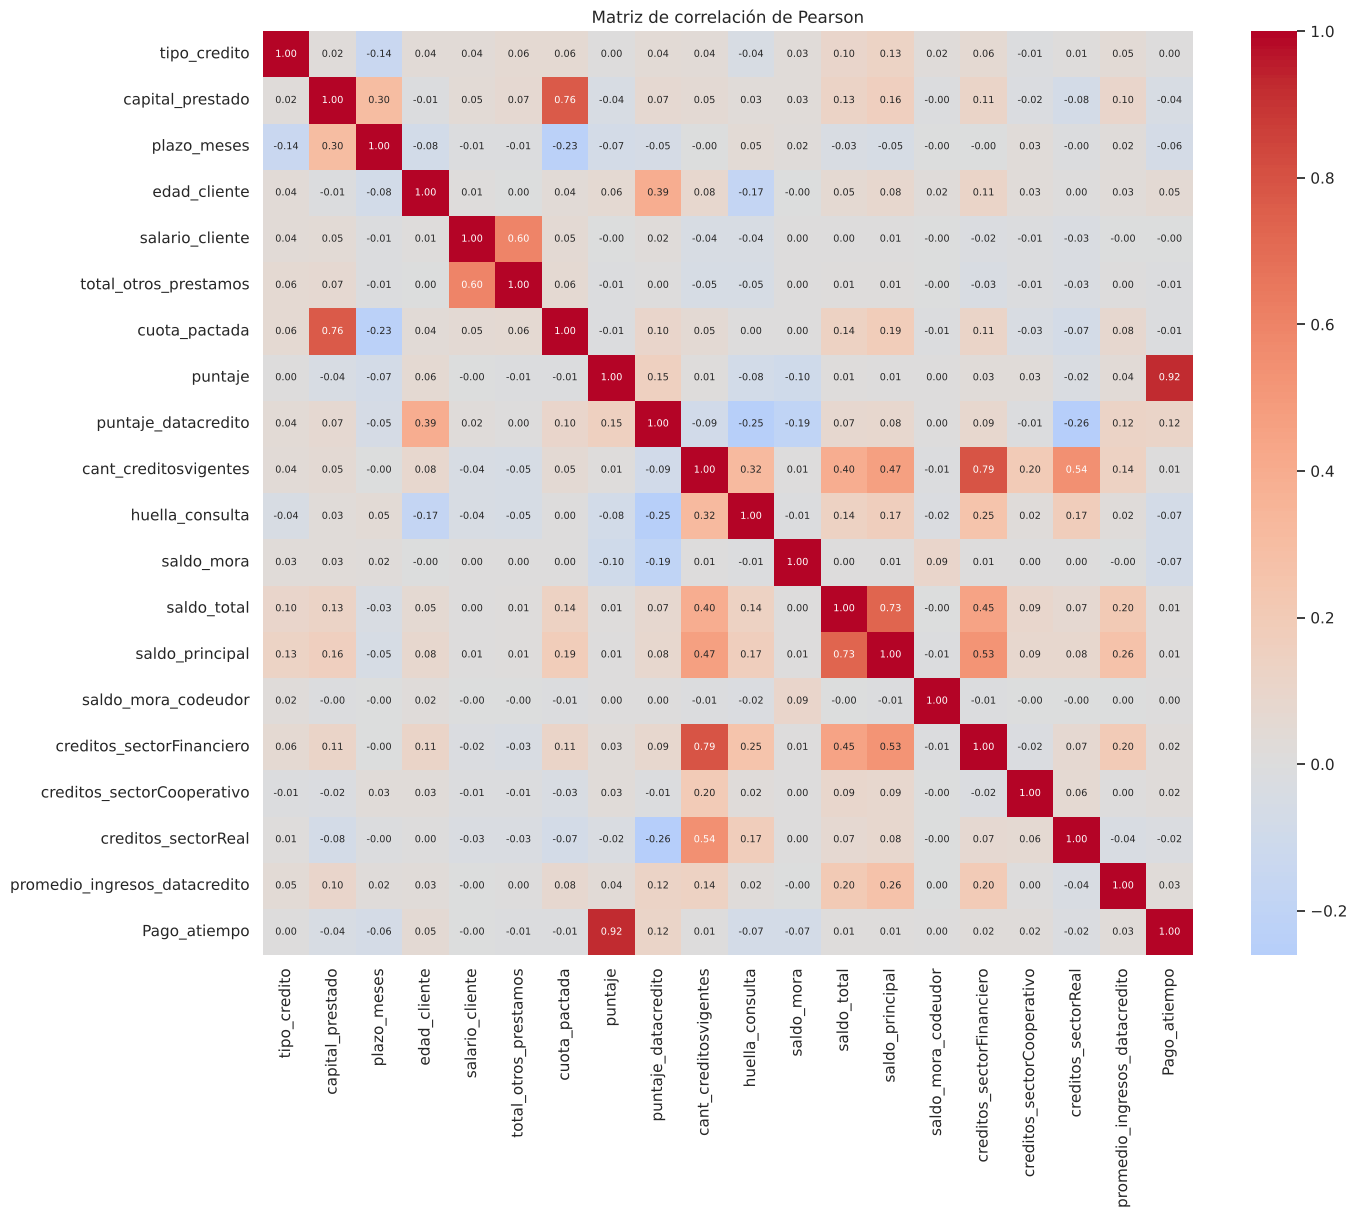

In [12]:
# Calcular la matriz de correlación entre todas las variables numéricas
corr = df[columnas_numericas].corr(method="pearson")

# Mapa de calor
plt.figure(figsize=(15, 12))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Matriz de correlación de Pearson")
plt.show()

In [13]:
# Correlación de cada variable con el objetivo, ordenada
corr["Pago_atiempo"].drop("Pago_atiempo").sort_values()

huella_consulta                 -0.073737
saldo_mora                      -0.072676
plazo_meses                     -0.063105
capital_prestado                -0.040624
creditos_sectorReal             -0.023306
cuota_pactada                   -0.011814
total_otros_prestamos           -0.010041
salario_cliente                 -0.003981
tipo_credito                     0.000951
saldo_mora_codeudor              0.002528
cant_creditosvigentes            0.008829
saldo_principal                  0.011148
saldo_total                      0.014211
creditos_sectorCooperativo       0.021267
creditos_sectorFinanciero        0.021390
promedio_ingresos_datacredito    0.032725
edad_cliente                     0.052253
puntaje_datacredito              0.118396
puntaje                          0.923134
Name: Pago_atiempo, dtype: float64

**Interpretación:** casi todas las variables tienen una correlación muy baja con `Pago_atiempo` (menos de 0,08), pero `puntaje` tiene **0,92**. Es sospechoso y lo revisamos a continuación.

### 5.1 Revisión de `puntaje`: ¿fuga de datos (data leakage)?

In [14]:
# Estadísticas del puntaje según si el cliente pagó o no
df.groupby("Pago_atiempo")["puntaje"].describe()

,count,mean,std,min,25%,50%,75%,max
Pago_atiempo,,,,,,,,
0,511.0,23.091216,26.070916,-38.009990,-3.591651,25.419455,47.613894,62.667613
1,10252.0,94.563352,2.873767,63.809656,95.227787,95.227787,95.227787,95.227787


In [15]:
# ¿Qué pasa con los clientes que tienen el puntaje máximo (95.23)?
puntaje_max = df["puntaje"].max()
es_max = df["puntaje"] == puntaje_max

print("Clientes con puntaje máximo:", es_max.sum())
print("Tasa de pago a tiempo con puntaje máximo     :", df.loc[es_max, "Pago_atiempo"].mean())
print("Tasa de pago a tiempo con puntaje por debajo :", round(df.loc[~es_max, "Pago_atiempo"].mean(), 3))

Clientes con puntaje máximo: 9407
Tasa de pago a tiempo con puntaje máximo     : 1.0
Tasa de pago a tiempo con puntaje por debajo : 0.623


**Conclusión (Opción A):** el 100 % de los clientes con puntaje máximo pagó a tiempo, y quienes no pagaron tienen puntajes muy bajos. Esto indica que `puntaje` probablemente se calculó **después** de conocer el comportamiento de pago. En producción, al aprobar un crédito, ese dato todavía no existe. Si lo usáramos, el modelo parecería perfecto en las pruebas y fallaría en la realidad.

**Decisión:** se elimina `puntaje` del modelo y se documenta como fuga de datos en el README.

In [16]:
# Antes de eliminar columnas, guardamos la lista de lo que se va eliminando
columnas_eliminadas = {}

df = df.drop(columns=["puntaje"])
columnas_eliminadas["puntaje"] = "Fuga de datos (r = 0.92 con el objetivo)"
print("Columnas actuales:", df.shape[1])

Columnas actuales: 22


### 5.2 Variables irrelevantes (|r| < 0.01 con `Pago_atiempo`)

In [17]:
# Antes de eliminar tipo_credito, revisemos su tasa de pago por código.
# (tipo_credito es un código nominal, así que Pearson no es la mejor herramienta para medirlo)
tabla_tipo = df.groupby("tipo_credito")["Pago_atiempo"].agg(["mean", "count"])
tabla_tipo

,mean,count
tipo_credito,,
4,0.953143,7747
6,0.571429,21
7,1.000000,2
9,0.952712,2876
10,0.974138,116
68,1.000000,1


Los códigos 4 y 9 concentran casi todos los créditos y tienen la misma tasa de pago (~95 %). Los demás códigos tienen muy pocos casos (menos de 120), así que no aportan información confiable. Es razonable eliminarla.

In [18]:
# Correlación de cada predictor con el objetivo (sin puntaje, ya eliminado)
corr_objetivo = corr["Pago_atiempo"].drop(["Pago_atiempo", "puntaje"])

# Variables con correlación absoluta menor a 0.01
irrelevantes = corr_objetivo[corr_objetivo.abs() < 0.01].index.tolist()
print("Variables irrelevantes:", irrelevantes)

df = df.drop(columns=irrelevantes)
for col in irrelevantes:
    columnas_eliminadas[col] = "Irrelevante (|r| < 0.01 con el objetivo)"
print("Columnas actuales:", df.shape[1])

Variables irrelevantes: ['tipo_credito', 'salario_cliente', 'cant_creditosvigentes', 'saldo_mora_codeudor']
Columnas actuales: 18


### 5.3 Variables redundantes (|r| > 0.75 entre predictores)

In [19]:
# Correlación entre predictores numéricos que quedan (sin el objetivo)
predictores_num = df.select_dtypes(include="number").columns.drop("Pago_atiempo")
corr_pred = df[predictores_num].corr().abs()

# Buscar parejas con correlación > 0.75
parejas = []
for i, col_a in enumerate(predictores_num):
    for col_b in predictores_num[i + 1:]:
        if corr_pred.loc[col_a, col_b] > 0.75:
            parejas.append((col_a, col_b, round(corr_pred.loc[col_a, col_b], 3)))

parejas

[('capital_prestado', 'cuota_pactada', np.float64(0.764))]

In [20]:
# De cada pareja redundante, eliminamos la variable que menos se relaciona con el objetivo
redundantes = []
for col_a, col_b, r in parejas:
    if abs(corr_objetivo[col_a]) < abs(corr_objetivo[col_b]):
        redundantes.append(col_a)
    else:
        redundantes.append(col_b)
redundantes = list(set(redundantes))
print("Variables redundantes:", redundantes)

df = df.drop(columns=redundantes)
for col in redundantes:
    columnas_eliminadas[col] = "Redundante (|r| > 0.75 con otro predictor)"

print("\nResumen de columnas eliminadas:")
for col, motivo in columnas_eliminadas.items():
    print(f"  - {col}: {motivo}")
print("\nColumnas finales:", df.shape[1])

Variables redundantes: ['cuota_pactada']

Resumen de columnas eliminadas:
  - puntaje: Fuga de datos (r = 0.92 con el objetivo)
  - tipo_credito: Irrelevante (|r| < 0.01 con el objetivo)
  - salario_cliente: Irrelevante (|r| < 0.01 con el objetivo)
  - cant_creditosvigentes: Irrelevante (|r| < 0.01 con el objetivo)
  - saldo_mora_codeudor: Irrelevante (|r| < 0.01 con el objetivo)
  - cuota_pactada: Redundante (|r| > 0.75 con otro predictor)

Columnas finales: 17


**Interpretación de negocio:** `cuota_pactada` es casi una función del capital prestado y del plazo; incluir ambas duplica información. Nos quedamos con `capital_prestado`, que se relaciona un poco más con el pago a tiempo.

## 6. Análisis univariable

### 6.1 Variable objetivo

Pago_atiempo
1    10252
0      511
Name: count, dtype: int64

Pago_atiempo
1    0.953
0    0.047
Name: proportion, dtype: float64


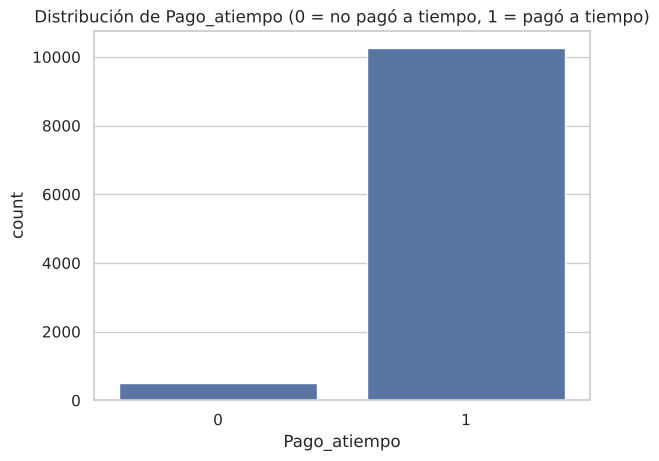

In [21]:
print(df["Pago_atiempo"].value_counts())
print()
print(df["Pago_atiempo"].value_counts(normalize=True).round(3))

sns.countplot(data=df, x="Pago_atiempo")
plt.title("Distribución de Pago_atiempo (0 = no pagó a tiempo, 1 = pagó a tiempo)")
plt.show()

**Interpretación:** el 95 % de los clientes paga a tiempo. Los datos están **muy desbalanceados**. Un modelo que prediga siempre "paga" tendría 95 % de exactitud pero no detectaría a ningún mal pagador. Por eso en el entrenamiento usaremos métricas como *recall*, *F1* y *ROC-AUC*, y no solo *accuracy*.

### 6.2 Variables numéricas

In [22]:
# Lista de variables numéricas predictoras
numericas = df.select_dtypes(include="number").columns.drop("Pago_atiempo").tolist()

# describe() con estadísticas básicas
df[numericas].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
capital_prestado,10763.0,2434315.00,1.909643e+06,360000.0,1224831.0,1921920.00,3084840.00,4.144415e+07
plazo_meses,10763.0,10.58,6.630000e+00,2.0,6.0,10.00,12.00,9.000000e+01
edad_cliente,10763.0,42.85,1.186000e+01,19.0,33.0,42.00,52.00,6.900000e+01
total_otros_prestamos,10763.0,6238869.65,1.184183e+08,0.0,500000.0,1000000.00,2000000.00,6.787675e+09
puntaje_datacredito,10763.0,791.53,5.107000e+01,7.0,759.0,791.53,825.00,9.990000e+02
huella_consulta,10763.0,4.23,3.060000e+00,0.0,2.0,4.00,6.00,2.900000e+01
saldo_mora,10763.0,7.75,2.243100e+02,0.0,0.0,0.00,0.00,1.253400e+04
saldo_total,10763.0,45937.41,1.054968e+05,0.0,3025.0,16763.00,52156.00,5.116066e+06
saldo_principal,10763.0,40346.17,6.988907e+04,0.0,2999.0,15838.00,45297.00,1.562285e+06
creditos_sectorFinanciero,10763.0,2.78,2.750000e+00,0.0,1.0,2.00,4.00,5.100000e+01


In [23]:
# Medidas de dispersión y forma de la distribución
estadisticas = pd.DataFrame({
    "media": df[numericas].mean(),
    "mediana": df[numericas].median(),
    "moda": df[numericas].mode().iloc[0],
    "rango": df[numericas].max() - df[numericas].min(),
    "IQR": df[numericas].quantile(0.75) - df[numericas].quantile(0.25),
    "varianza": df[numericas].var(),
    "desv_est": df[numericas].std(),
    "skewness": df[numericas].skew(),
    "kurtosis": df[numericas].kurt(),
})
estadisticas.round(2)

,media,mediana,moda,rango,IQR,varianza,desv_est,skewness,kurtosis
capital_prestado,2434315.00,1921920.00,1200000.00,4.108415e+07,1860009.00,3.646735e+12,1.909643e+06,3.72,35.32
plazo_meses,10.58,10.00,6.00,8.800000e+01,6.00,4.398000e+01,6.630000e+00,2.46,7.78
edad_cliente,42.85,42.00,40.00,5.000000e+01,19.00,1.407500e+02,1.186000e+01,0.27,-0.83
total_otros_prestamos,6238869.65,1000000.00,2000000.00,6.787675e+09,1500000.00,1.402290e+16,1.184183e+08,38.46,1719.28
puntaje_datacredito,791.53,791.53,791.53,9.920000e+02,66.00,2.607990e+03,5.107000e+01,-1.00,10.16
huella_consulta,4.23,4.00,2.00,2.900000e+01,4.00,9.390000e+00,3.060000e+00,1.49,4.00
saldo_mora,7.75,0.00,0.00,1.253400e+04,0.00,5.031564e+04,2.243100e+02,40.87,1872.89
saldo_total,45937.41,16763.00,0.00,5.116066e+06,49131.00,1.112957e+10,1.054968e+05,20.35,800.81
saldo_principal,40346.17,15838.00,0.00,1.562285e+06,42298.00,4.884483e+09,6.988907e+04,5.15,53.18
creditos_sectorFinanciero,2.78,2.00,1.00,5.100000e+01,3.00,7.560000e+00,2.750000e+00,2.70,19.44


**Interpretación:**
- La mayoría de variables de dinero y saldos tienen **skewness alta y positiva** (asimetría a la derecha): muchos clientes con valores bajos y unos pocos con valores muy altos. Son distribuciones tipo **log-normal / exponencial**, no gaussianas.
- La kurtosis muy alta indica **valores atípicos** (colas pesadas).
- Esto sugiere aplicar transformación logarítmica o escalado robusto en la ingeniería de características.

In [24]:
# Identificar el TIPO DE DISTRIBUCIÓN de cada variable numérica
# Usamos asimetría (skewness), curtosis y la prueba de normalidad de D'Agostino (p < 0.05 = NO es gaussiana)
from scipy import stats

filas_dist = []
for col in numericas:
    asimetria = df[col].skew()
    curtosis = df[col].kurt()
    n_unicos = df[col].nunique()
    p_normalidad = stats.normaltest(df[col])[1]

    if n_unicos <= 40:
        tipo = "Discreta (conteo)" + (", sesgada a la derecha" if asimetria > 1 else "")
    elif asimetria > 1:
        tipo = "Asimétrica a la derecha (log-normal / exponencial)"
    elif asimetria < -0.5:
        tipo = "Asimétrica a la izquierda"
    elif abs(asimetria) < 0.5:
        tipo = "Aprox. simétrica" + (", más plana que la normal (tipo uniforme)" if curtosis < -0.5 else "")
    else:
        tipo = "Moderadamente asimétrica"

    filas_dist.append({"variable": col, "asimetria": round(asimetria, 2), "curtosis": round(curtosis, 1),
                       "valores_unicos": n_unicos, "es_gaussiana": p_normalidad > 0.05, "tipo_distribucion": tipo})

pd.DataFrame(filas_dist).set_index("variable")

,asimetria,curtosis,valores_unicos,es_gaussiana,tipo_distribucion
variable,,,,,
capital_prestado,3.72,35.3,7306,False,Asimétrica a la derecha (log-normal / exponenc...
plazo_meses,2.46,7.8,18,False,"Discreta (conteo), sesgada a la derecha"
edad_cliente,0.27,-0.8,52,False,"Aprox. simétrica, más plana que la normal (tip..."
total_otros_prestamos,38.46,1719.3,1538,False,Asimétrica a la derecha (log-normal / exponenc...
puntaje_datacredito,-1.00,10.2,314,False,Asimétrica a la izquierda
huella_consulta,1.49,4.0,28,False,"Discreta (conteo), sesgada a la derecha"
saldo_mora,40.87,1872.9,56,False,Asimétrica a la derecha (log-normal / exponenc...
saldo_total,20.35,800.8,8859,False,Asimétrica a la derecha (log-normal / exponenc...
saldo_principal,5.15,53.2,8648,False,Asimétrica a la derecha (log-normal / exponenc...


**Interpretación:** ninguna variable pasa la prueba de normalidad, es decir, **ninguna es gaussiana**.
- **Montos y saldos** (`capital_prestado`, `total_otros_prestamos`, `saldo_*`, `promedio_ingresos_datacredito`): asimétricas a la derecha, tipo log-normal o exponencial, con colas muy pesadas (pocos clientes con valores enormes).
- **Conteos** (`plazo_meses`, `huella_consulta`, `creditos_sector*`): discretas, con muchos valores bajos y pocos altos.
- **`edad_cliente`:** aproximadamente simétrica pero más plana que una normal, es decir, las edades se reparten de forma más pareja entre los clientes adultos.
- **`puntaje_datacredito`:** asimétrica a la izquierda (la mayoría tiene puntajes altos y pocos tienen puntajes muy bajos).
- **Consecuencia práctica:** conviene escalar las variables y usar modelos robustos a valores extremos, como los basados en árboles.

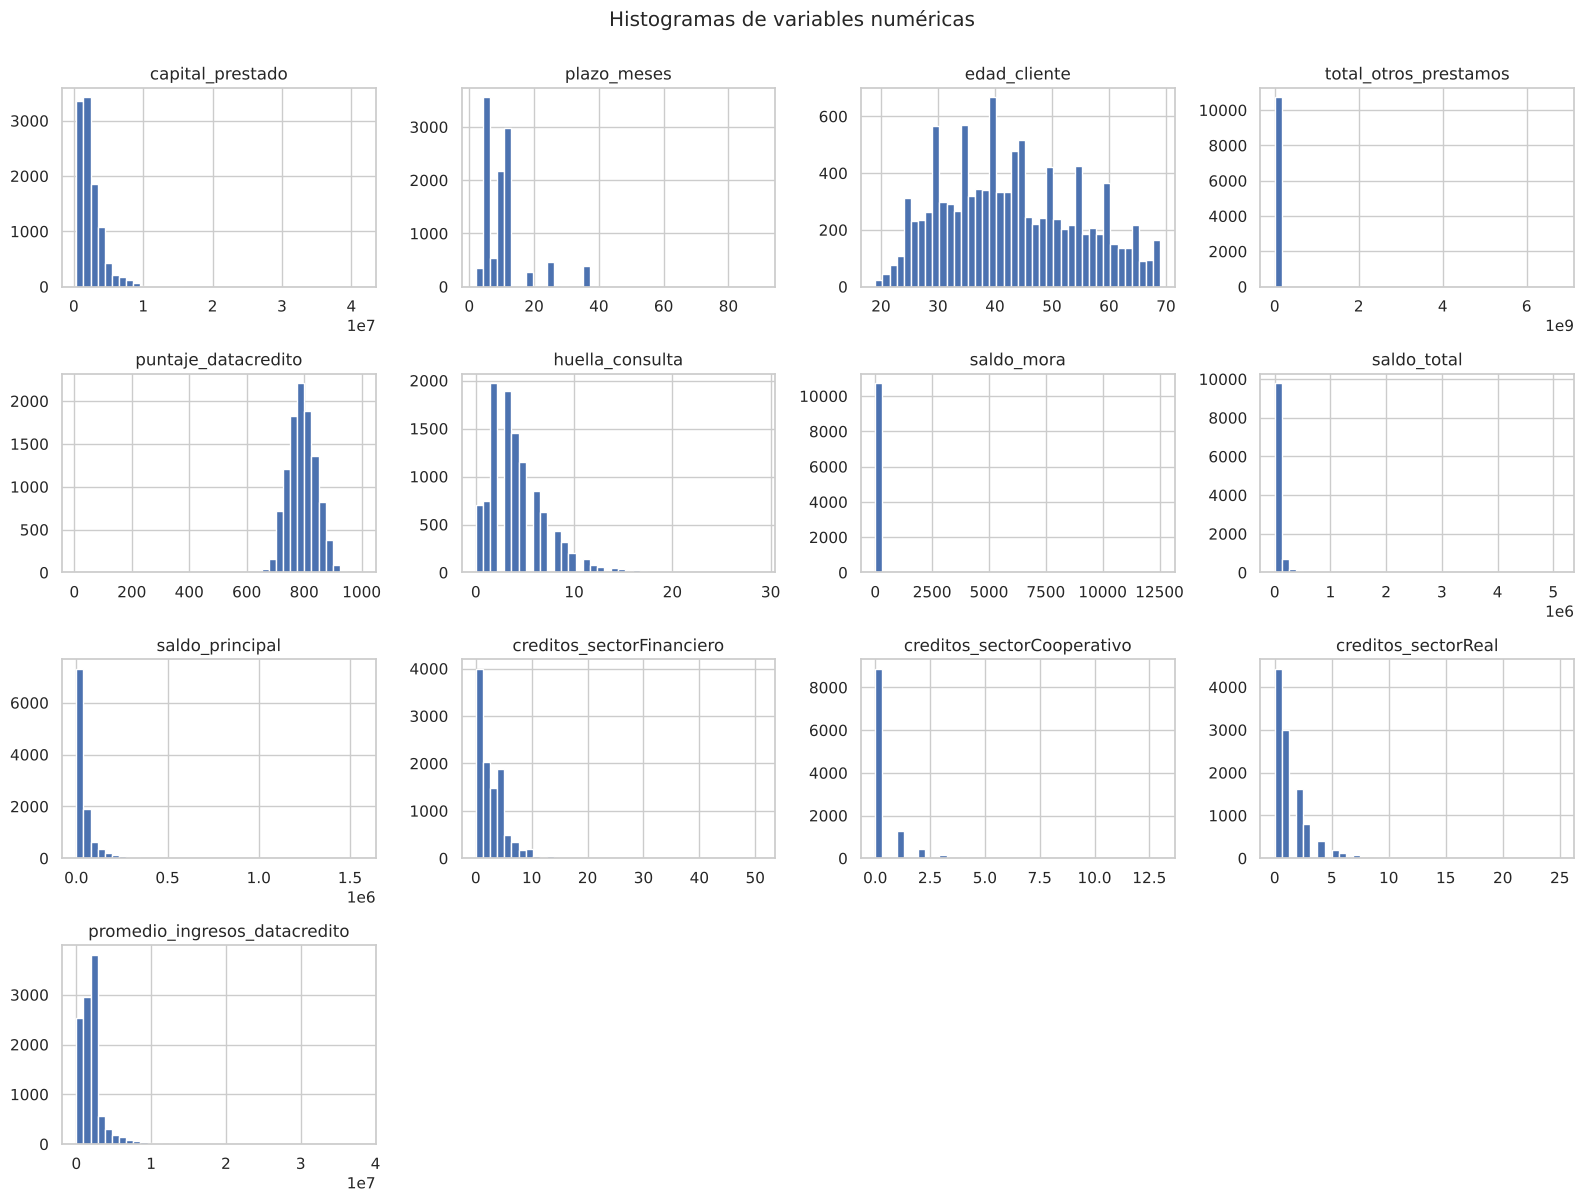

In [25]:
# Histogramas: forma de la distribución de cada variable
df[numericas].hist(bins=40, figsize=(16, 12))
plt.suptitle("Histogramas de variables numéricas", y=1.0)
plt.tight_layout()
plt.show()

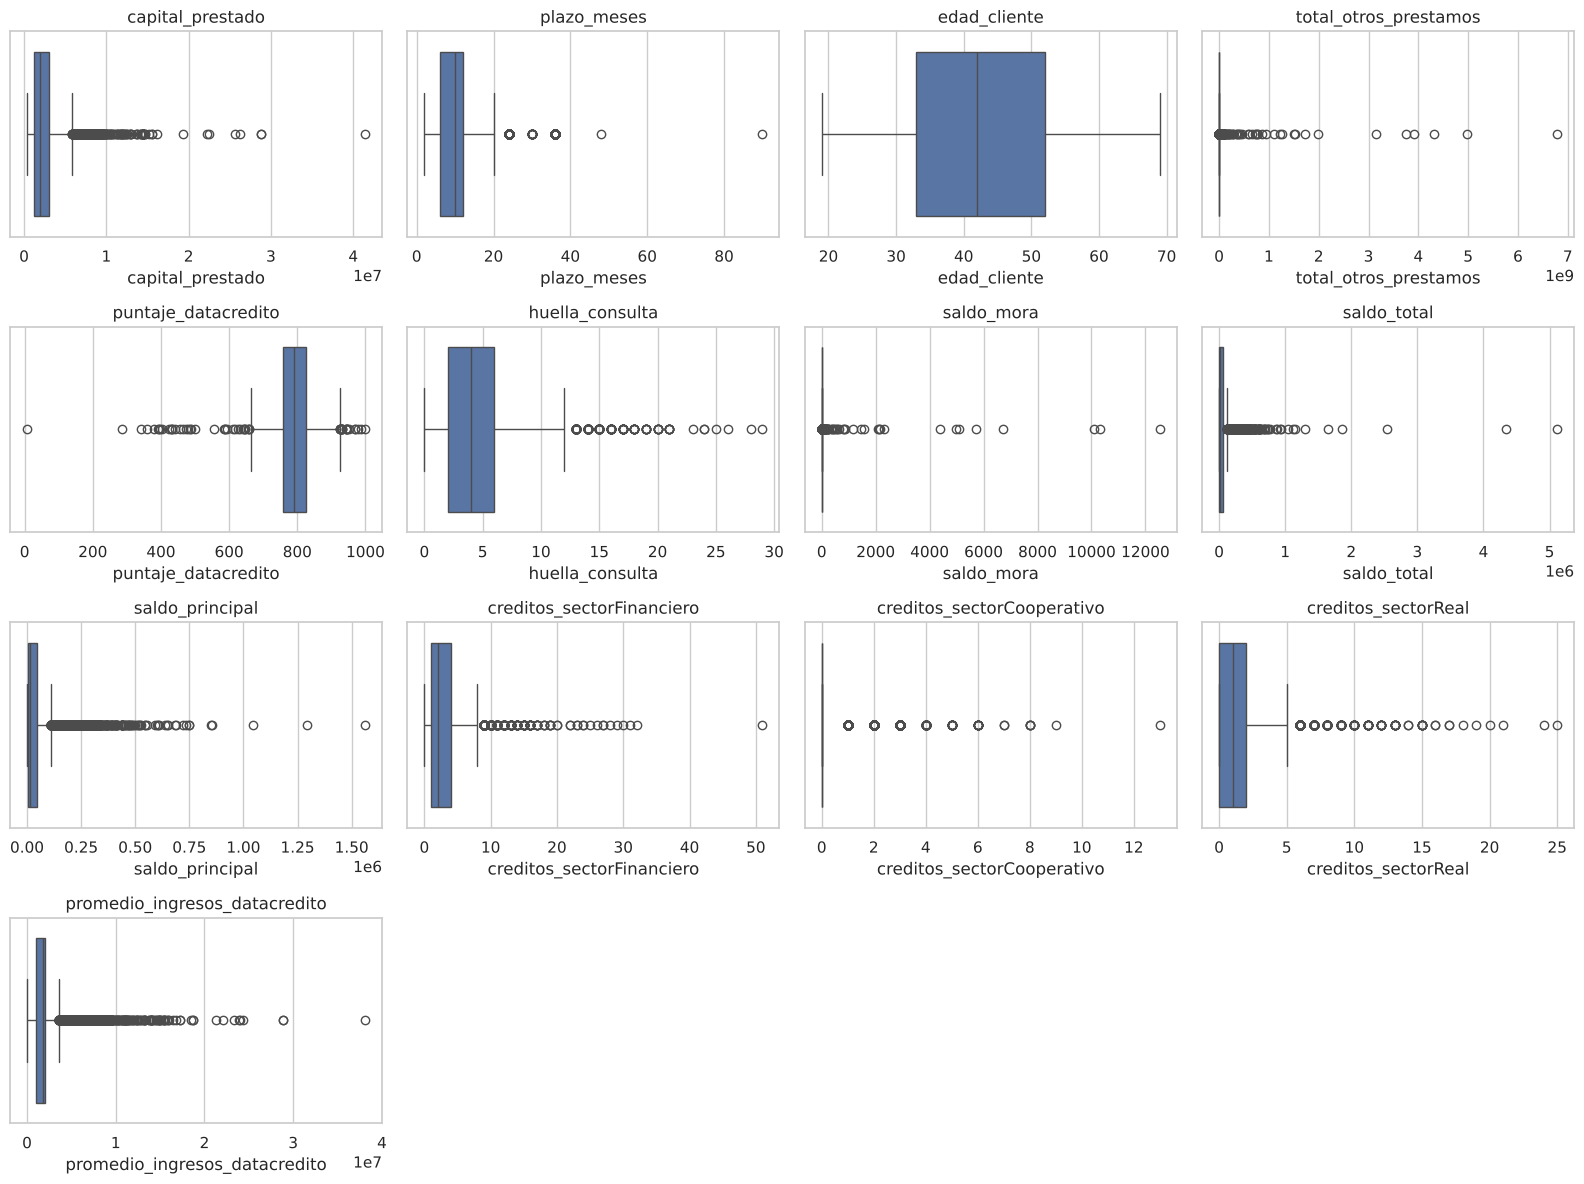

In [26]:
# Boxplots: detectar valores atípicos
filas = int(np.ceil(len(numericas) / 4))
fig, ejes = plt.subplots(filas, 4, figsize=(16, 3 * filas))
ejes = ejes.flatten()

for i, col in enumerate(numericas):
    sns.boxplot(x=df[col], ax=ejes[i])
    ejes[i].set_title(col)

# Ocultar los ejes que sobran
for j in range(len(numericas), len(ejes)):
    ejes[j].set_visible(False)

plt.tight_layout()
plt.show()

### 6.3 Variables categóricas

tipo_laboral
Empleado         6754
Independiente    4009
Name: count, dtype: int64

tendencia_ingresos
Creciente      5294
Sin_dato       2990
Decreciente    1291
Estable        1188
Name: count, dtype: int64



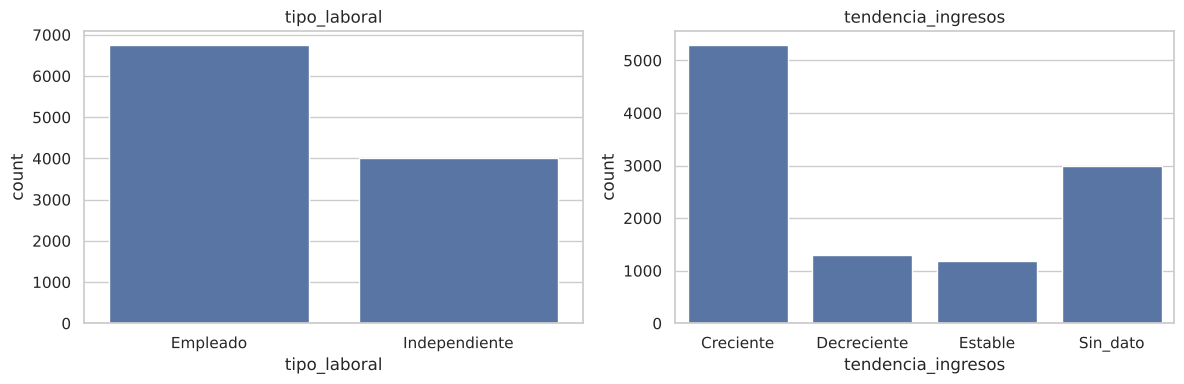

In [27]:
categoricas = ["tipo_laboral", "tendencia_ingresos"]

for col in categoricas:
    print(df[col].value_counts())
    print()

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for i, col in enumerate(categoricas):
    sns.countplot(data=df, x=col, ax=ejes[i])
    ejes[i].set_title(col)
plt.tight_layout()
plt.show()

**Interpretación:** 63 % de los clientes son empleados y 37 % independientes. En `tendencia_ingresos`, la categoría más grande es "Creciente", seguida de los clientes "Sin_dato" (cerca de 28 %).

## 7. Análisis bivariable (contra `Pago_atiempo`)

### 7.1 Variables categóricas: tasa de pago a tiempo

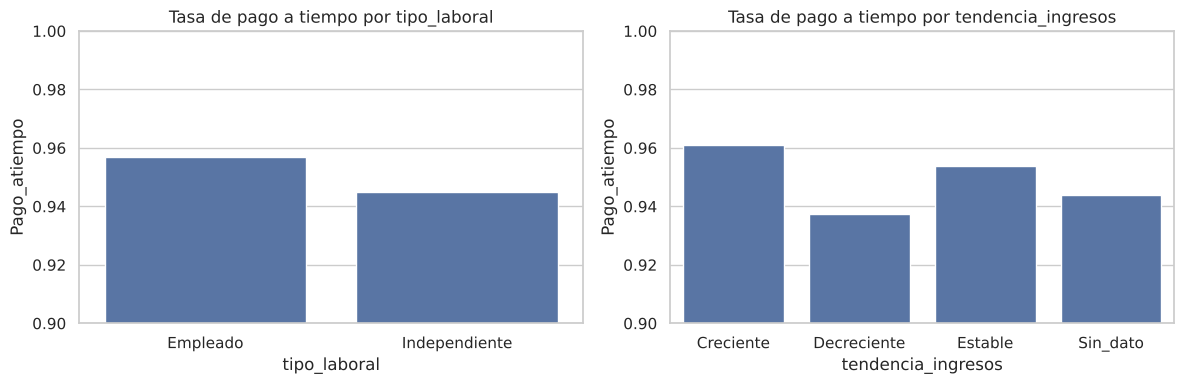

,mean,count
tendencia_ingresos,,
Creciente,0.961,5294
Decreciente,0.937,1291
Estable,0.954,1188
Sin_dato,0.944,2990


In [28]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for i, col in enumerate(categoricas):
    tasa = df.groupby(col, observed=True)["Pago_atiempo"].mean().reset_index()
    sns.barplot(data=tasa, x=col, y="Pago_atiempo", ax=ejes[i])
    ejes[i].set_ylim(0.9, 1.0)
    ejes[i].set_title(f"Tasa de pago a tiempo por {col}")
plt.tight_layout()
plt.show()

df.groupby("tendencia_ingresos", observed=True)["Pago_atiempo"].agg(["mean", "count"]).round(3)

**Interpretación de negocio:**
- Los **empleados** pagan a tiempo un poco más (95,7 %) que los **independientes** (94,5 %).
- Los clientes con ingresos **crecientes** son los mejores pagadores (96,1 %) y los de ingresos **decrecientes** los más riesgosos (93,7 %).
- Las diferencias son pequeñas (1 a 2 puntos), pero consistentes con la lógica del negocio. Ojo: el eje empieza en 0,9 para hacerlas visibles.

### 7.2 Variables numéricas según el resultado de pago

In [29]:
# Mediana de cada variable para quienes pagaron (1) y no pagaron (0)
df.groupby("Pago_atiempo")[numericas].median().T.round(1)

Pago_atiempo,0,1
capital_prestado,2268000.0,1908446.4
plazo_meses,10.0,10.0
edad_cliente,38.0,42.0
total_otros_prestamos,900000.0,1000000.0
puntaje_datacredito,770.0,792.0
huella_consulta,5.0,4.0
saldo_mora,0.0,0.0
saldo_total,14981.0,16860.5
saldo_principal,14869.0,15898.0
creditos_sectorFinanciero,2.0,2.0


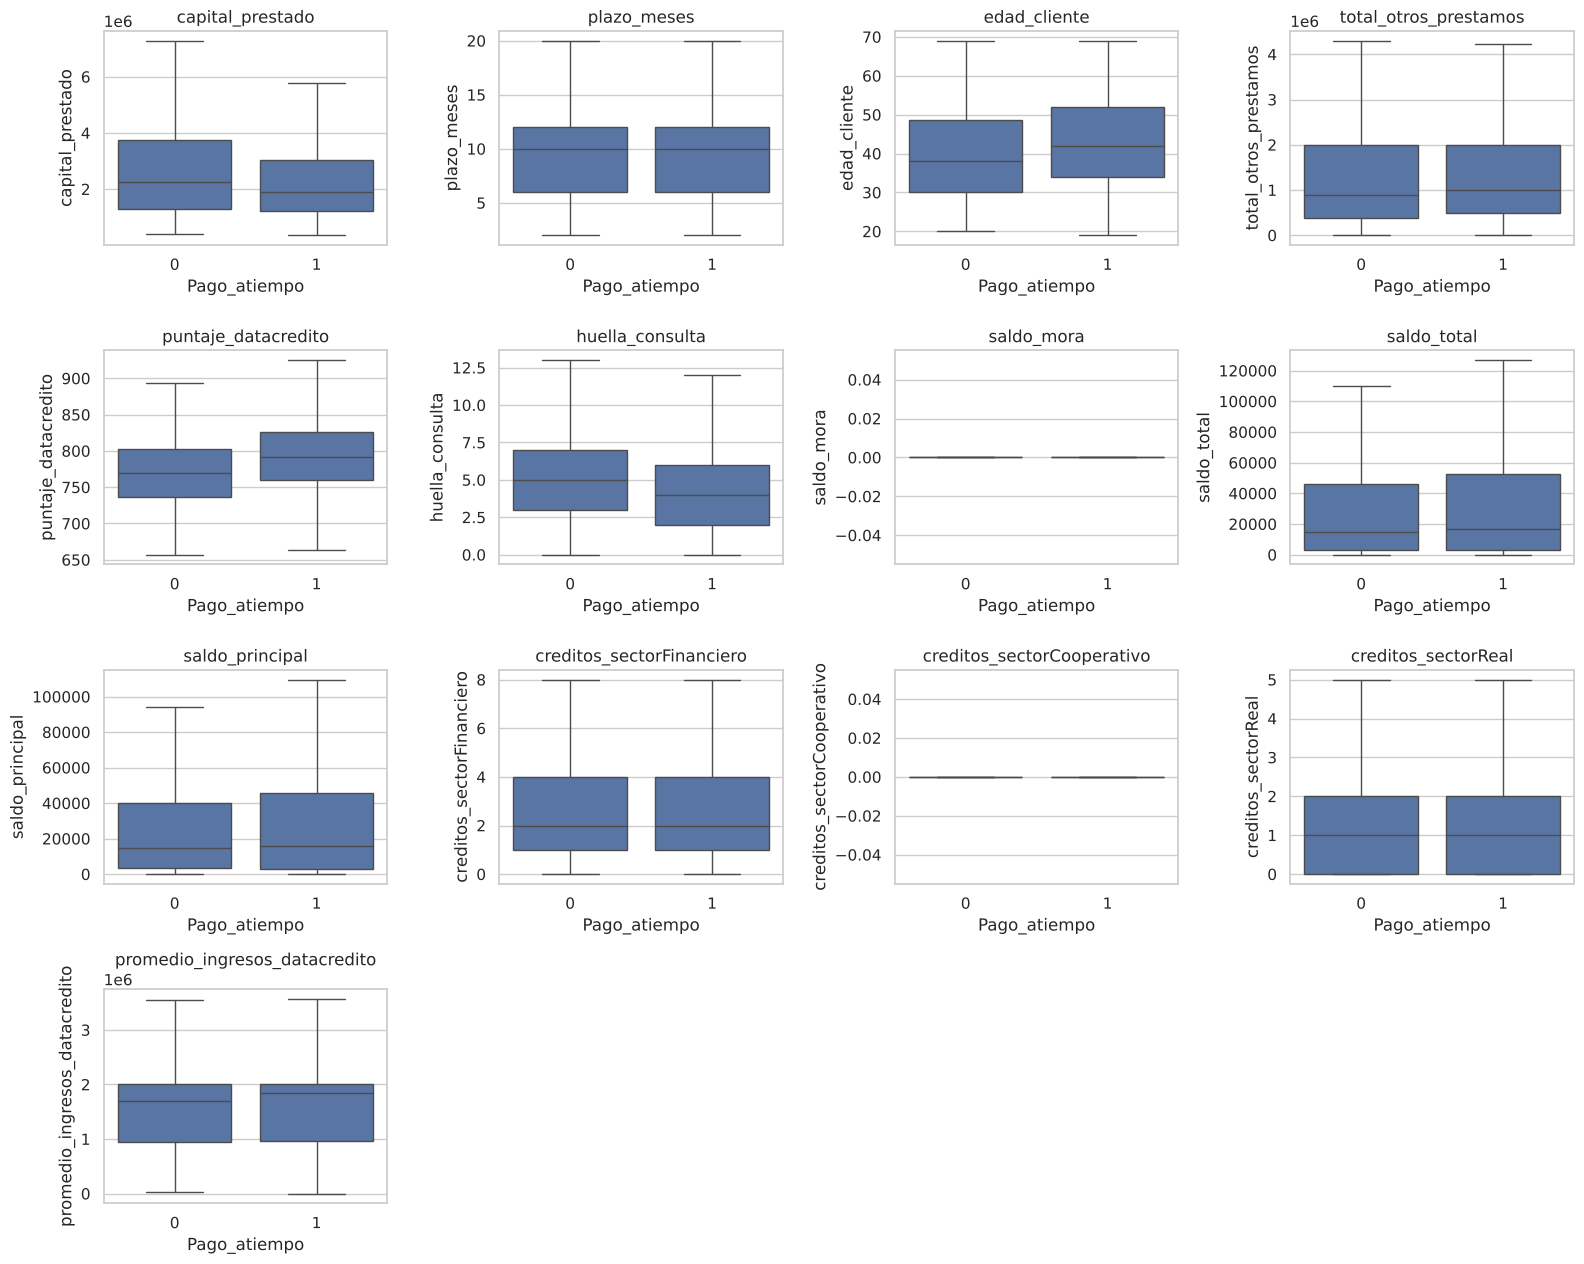

In [30]:
# Boxplots por grupo (sin mostrar los puntos atípicos para poder ver las cajas)
fig, ejes = plt.subplots(filas, 4, figsize=(16, 3.2 * filas))
ejes = ejes.flatten()

for i, col in enumerate(numericas):
    sns.boxplot(data=df, x="Pago_atiempo", y=col, showfliers=False, ax=ejes[i])
    ejes[i].set_title(col)

for j in range(len(numericas), len(ejes)):
    ejes[j].set_visible(False)

plt.tight_layout()
plt.show()

**Interpretación de negocio** (grupo que NO paga a tiempo frente al que sí paga):
- Piden **más capital** (mediana de 2,27 M frente a 1,91 M).
- Tienen **más consultas a su historial** (`huella_consulta`: 5 frente a 4). Buscar crédito en muchos sitios puede ser señal de necesidad de liquidez.
- Tienen **menor puntaje en Datacrédito** (768 frente a 792).
- Tienen **menores ingresos promedio** (1,05 M frente a 1,21 M).
- Ninguna variable por sí sola separa bien a los grupos; el modelo tendrá que combinarlas.

## 8. Análisis multivariable

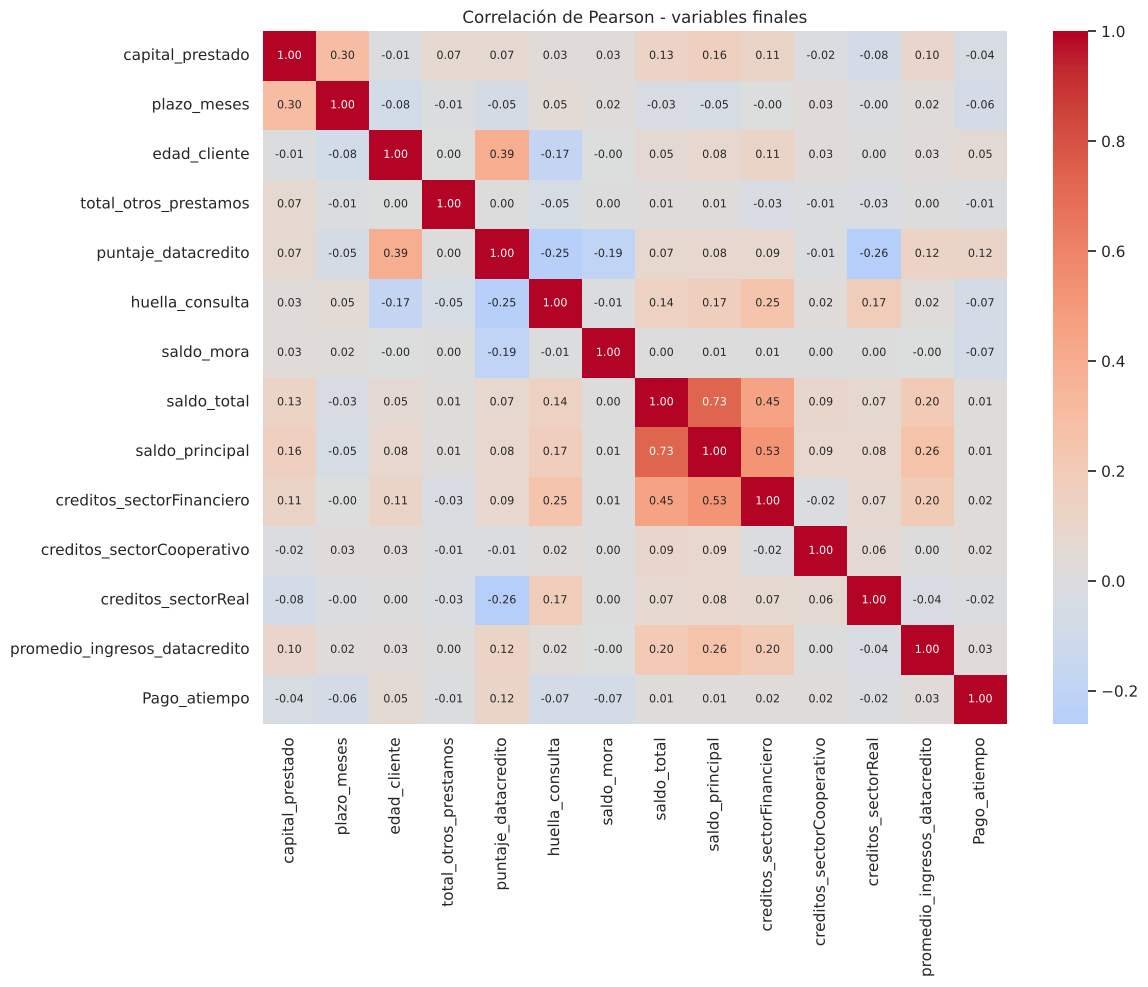

In [31]:
# Matriz de correlación final (solo variables que se conservan)
columnas_final = df.select_dtypes(include="number").columns
plt.figure(figsize=(12, 9))
sns.heatmap(df[columnas_final].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Correlación de Pearson - variables finales")
plt.show()

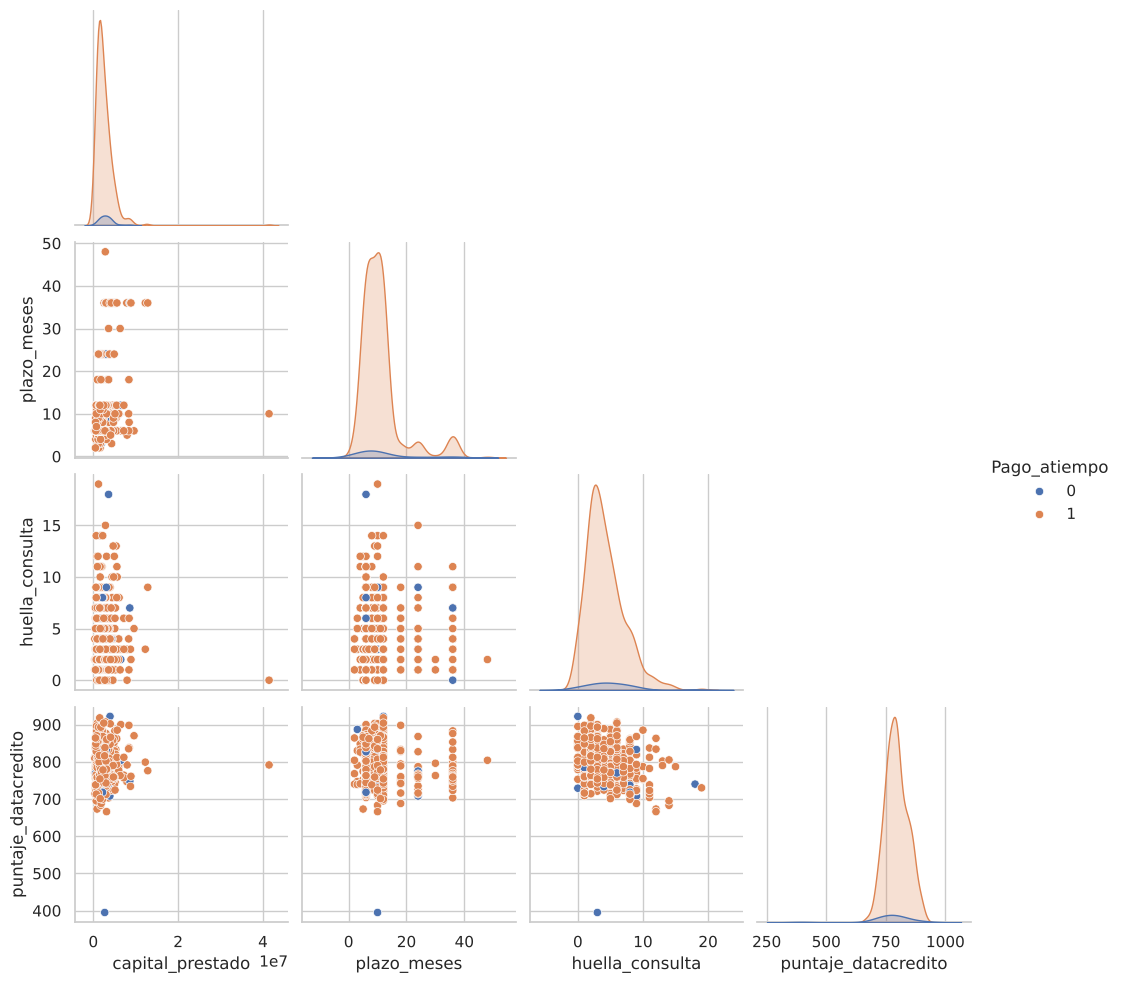

In [32]:
# Pairplot con una muestra (500 filas) para que no sea lento; color según el objetivo
muestra = df.sample(500, random_state=42)
sns.pairplot(muestra, vars=["capital_prestado", "plazo_meses", "huella_consulta", "puntaje_datacredito"],
             hue="Pago_atiempo", corner=True)
plt.show()

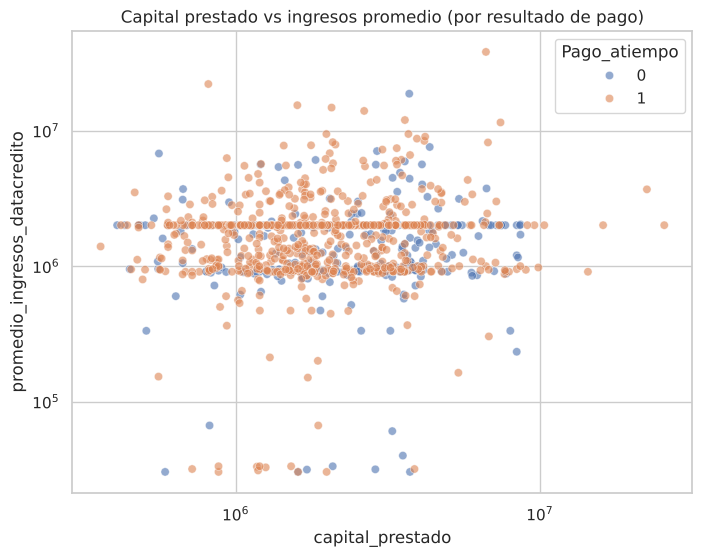

In [33]:
# Gráfico de dispersión con hue: capital prestado vs ingresos, coloreado por el resultado de pago
# Tomamos todos (hasta 300) los que NO pagan y 700 de los que sí, para que ambos grupos se vean.
# Usamos escala logarítmica porque ambas variables tienen valores extremos.
no_pagan = df[df["Pago_atiempo"] == 0].sample(300, random_state=42)
si_pagan = df[df["Pago_atiempo"] == 1].sample(700, random_state=42)
muestra_disp = pd.concat([no_pagan, si_pagan])

plt.figure(figsize=(8, 6))
sns.scatterplot(data=muestra_disp, x="capital_prestado", y="promedio_ingresos_datacredito",
                hue="Pago_atiempo", alpha=0.6)
plt.xscale("log")
plt.yscale("log")
plt.title("Capital prestado vs ingresos promedio (por resultado de pago)")
plt.show()

**Interpretación:** los dos grupos se **superponen casi por completo**: no hay una frontera visual que separe a quienes pagan de quienes no. Esto explica por qué el modelo logra un rendimiento moderado (AUC cercano a 0,70) y confirma que la señal está repartida entre varias variables débiles. La línea horizontal de puntos corresponde a los clientes sin dato de ingresos, imputados con la media.

In [34]:
# Tabla cruzada: tasa de pago según tipo laboral y tendencia de ingresos
pd.pivot_table(df, values="Pago_atiempo", index="tipo_laboral", columns="tendencia_ingresos",
               aggfunc="mean", observed=True).round(3)

tendencia_ingresos,Creciente,Decreciente,Estable,Sin_dato
tipo_laboral,,,,
Empleado,0.964,0.941,0.955,0.948
Independiente,0.952,0.927,0.952,0.940


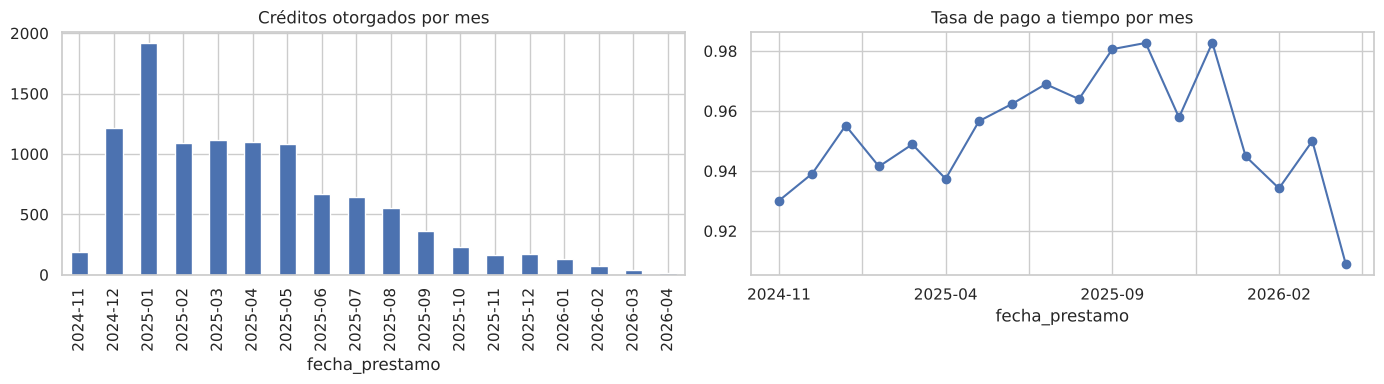

In [35]:
# Evolución mensual: ¿cambia el comportamiento con el tiempo? (importante para el monitoreo de drift)
mensual = df.groupby(df["fecha_prestamo"].dt.to_period("M"))["Pago_atiempo"].agg(["mean", "count"])
mensual.index = mensual.index.astype(str)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
mensual["count"].plot(kind="bar", ax=ejes[0], title="Créditos otorgados por mes")
mensual["mean"].plot(marker="o", ax=ejes[1], title="Tasa de pago a tiempo por mes")
plt.tight_layout()
plt.show()

**Interpretación:**
- Las variables finales tienen correlaciones de bajas a moderadas entre sí. La más alta es `saldo_principal` con `saldo_total` (0,73), que queda por debajo del umbral de 0,75 y por eso se conserva. Los saldos también se relacionan con `creditos_sectorFinanciero` (0,45 a 0,53).
- El volumen de créditos **cae con el tiempo** (más de 1.900 en enero de 2025 y menos de 250 desde octubre de 2025). Esto es una señal de que la población puede cambiar, y por eso el monitoreo de *data drift* será importante.

## 9. Calidad de datos y reglas de validación

In [36]:
# Buscar valores sospechosos en los datos ORIGINALES (antes de limpiar)
original = pd.read_csv("../Base_de_datos.csv")

print("Edades mayores a 90 años        :", (original["edad_cliente"] > 90).sum())
print("Edades menores a 18 años        :", (original["edad_cliente"] < 18).sum())
print("Salarios iguales a 0            :", (original["salario_cliente"] == 0).sum())
print("Salarios mayores a 50 millones  :", (original["salario_cliente"] > 50_000_000).sum())
print("Puntaje Datacrédito <= 0        :", (original["puntaje_datacredito"] <= 0).sum())
print("Plazo mayor a 60 meses          :", (original["plazo_meses"] > 60).sum())
print("\nEdades mayores a 90 y cuántas veces aparecen:")
print(original.loc[original["edad_cliente"] > 90, "edad_cliente"].value_counts())

Edades mayores a 90 años        : 150
Edades menores a 18 años        : 0
Salarios iguales a 0            : 24
Salarios mayores a 50 millones  : 97
Puntaje Datacrédito <= 0        : 146
Plazo mayor a 60 meses          : 1

Edades mayores a 90 y cuántas veces aparecen:
edad_cliente
122    144
121      4
123      2
Name: count, dtype: int64


### Reglas de validación propuestas (se usarán en `ft_engineering.py` y en la API)

| Variable | Regla | Qué hacer si no se cumple |
|---|---|---|
| `edad_cliente` | Entre 18 y 90 | Tratar como nulo (el valor 122 aparece 144 veces y parece un código de dato faltante) |
| `puntaje_datacredito` | Mayor a 0 | Tratar como nulo |
| `capital_prestado`, `cuota_pactada` | Mayor a 0 | Rechazar el registro |
| `plazo_meses` | Entre 1 y 60 | Rechazar o revisar |
| `tipo_laboral` | Solo `Empleado` o `Independiente` | Rechazar el registro |
| `tendencia_ingresos` | Solo `Creciente`, `Decreciente`, `Estable` o `Sin_dato` | Reemplazar por `Sin_dato` |
| Saldos y conteos | Mayores o iguales a 0 | Rechazar el registro |

### Transformaciones recomendadas
- **Escalado** de las numéricas (con `StandardScaler`, o `RobustScaler` si se quiere menos efecto de los atípicos).
- **One-Hot Encoding** para `tipo_laboral` y `tendencia_ingresos`.
- **Balanceo de clases** (`class_weight="balanced"`) porque solo el 5 % son malos pagadores.
- Excluir `fecha_prestamo` de los predictores (se conserva para el monitoreo temporal).

### Variables derivadas que podrían ayudar
- **Relación cuota/ingreso:** `cuota_pactada / promedio_ingresos_datacredito` (capacidad de pago). Ojo: `cuota_pactada` se eliminó por redundancia, así que se construiría antes de eliminarla.
- **Relación saldo en mora / saldo total:** qué porcentaje de la deuda ya está en mora.
- **Total de créditos por sector:** suma de financiero + cooperativo + real.
- **Mes del préstamo**, para estudiar estacionalidad.

In [37]:
# Resumen final de lo que queda para el modelado
print("Columnas finales:")
print(df.dtypes)
print("\nForma final:", df.shape)

Columnas finales:
fecha_prestamo                   datetime64[us]
capital_prestado                        float64
plazo_meses                               int64
edad_cliente                            float64
tipo_laboral                           category
total_otros_prestamos                     int64
puntaje_datacredito                     float64
huella_consulta                           int64
saldo_mora                              float64
saldo_total                             float64
saldo_principal                         float64
creditos_sectorFinanciero                 int64
creditos_sectorCooperativo                int64
creditos_sectorReal                       int64
promedio_ingresos_datacredito           float64
tendencia_ingresos                     category
Pago_atiempo                              int64
dtype: object

Forma final: (10763, 17)


## 10. Conclusiones del EDA

1. La base tiene 10.763 créditos y está **muy desbalanceada** (95 % paga a tiempo).
2. `puntaje` es una **fuga de datos** y se excluye del modelo.
3. Se eliminaron `tipo_credito`, `salario_cliente`, `cant_creditosvigentes` y `saldo_mora_codeudor` por irrelevantes, y `cuota_pactada` por redundante.
4. Las variables restantes tienen señales **débiles pero coherentes** con el negocio: más consultas, mayor capital, menores ingresos y peor puntaje de Datacrédito se asocian con más mora.
5. Había **datos inválidos** (edades de 122 años, puntajes de Datacrédito menores o iguales a 0). Se convirtieron en nulos y se imputaron con la media; la misma regla se aplica en `ft_engineering.py`. Los valores atípicos de montos y saldos se conservan y se manejan con escalado y modelos de árboles.
6. El volumen de créditos baja con el tiempo, lo cual justifica el monitoreo de *data drift*.